In [28]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [29]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp



# This notebook contains example usage of the 0D solver class for avalanching  #

## Initialize solver ##

In [30]:
solver = RE.solver0D()
solver.display() # Show default values


 Constants:
Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0
tmax [s] = 0.005
Zeff_scale [-] =1.0
device [-] = SPARC


### Change to SPARC like conditions and solve ###

In [31]:
solver.Z_imp = 10
solver.A_imp = 20
solver.n_imp = 1e20
solver.Tf = 10
solver.T0 = 20e3
solver.nD = 2 * solver.n_imp
solver.iDreicer = 1
solver.tmax = 15e-3
solver.Ir0 = 10000
solver.k = 1.7

solver.idiag = True # calculate detailed output
t, Ip, Ir, Wk = solver.solve()

### Display solution ###

Text(0.5, 1.0, '10kA, n_imp=1e20, 2 times deuterium')

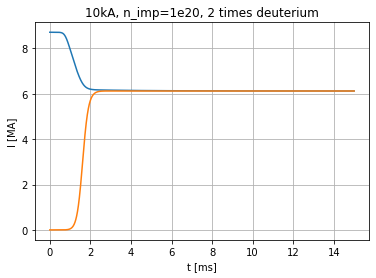

In [32]:
plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title('10kA, n_imp=1e20, 2 times deuterium')

### View details ###

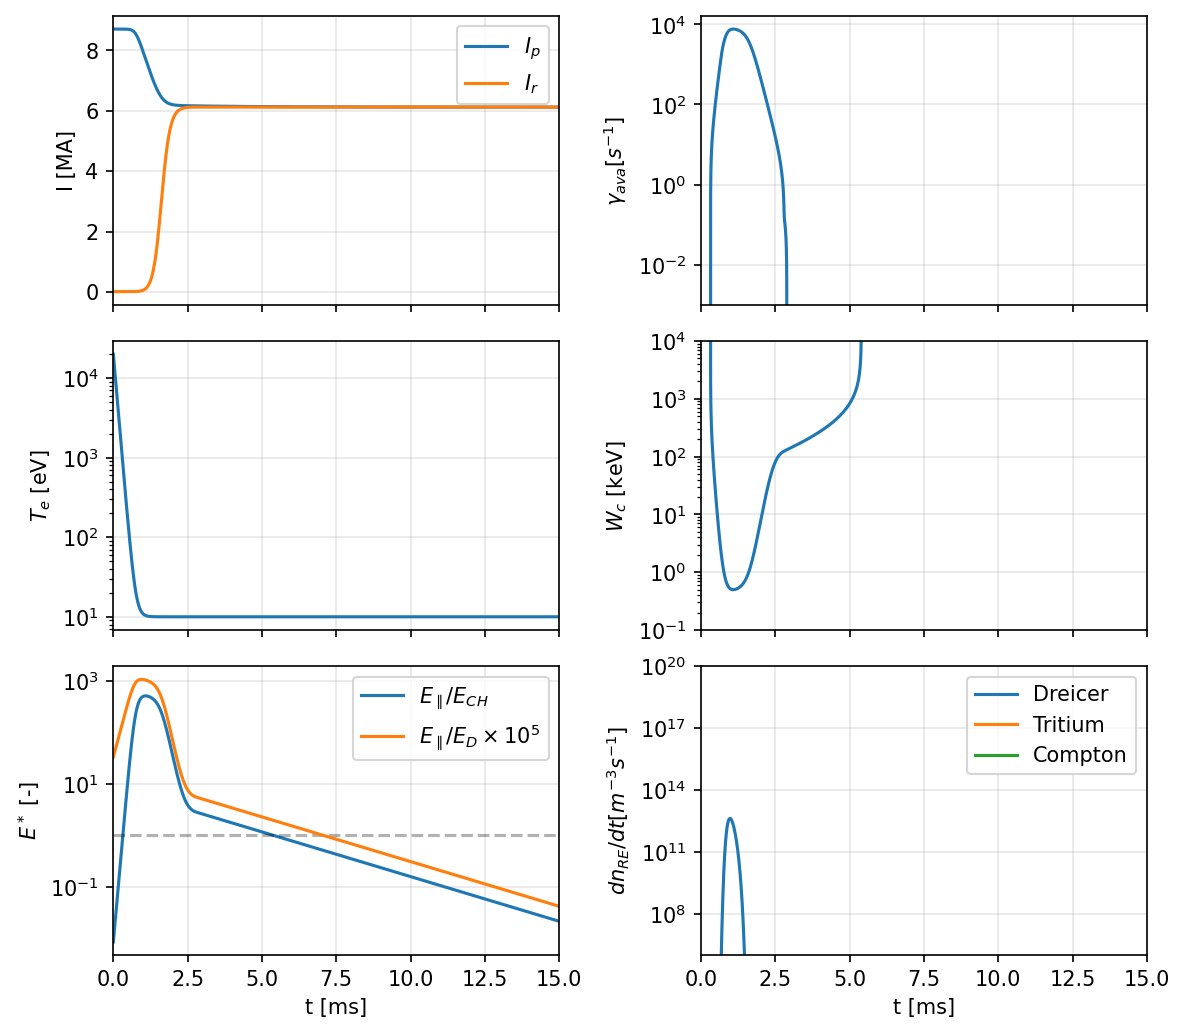

In [33]:
# Use the dictionary stored inside the solver object
d = solver.diag

fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
axs[1, 0].set_yscale('log')

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()

for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, d['t'].max() * 1e3])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()